# Covariance matrix and the multivariate normal: Data section
**Ty'Kuan** · CMAT 651 · Teaching rotation, Fri Oct 30

**Dataset:** WNBA 2025 shot data, one row per shot. We look at three numeric columns:
- `shot_distance`: how far the shot was from the basket, in feet
- `loc_y`: where the shot was taken up the court from the basket, in tenths of a foot
- `seconds_left`: seconds left in the period when the shot was taken

The full file is used for every number here. Nothing in this notebook is random, so there is no sampling and no seed to set.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

DATA = "/Users/grindhardt/Desktop/Python/Project STAT/wnba_clean.csv"
df = pd.read_csv(DATA)
print("shape:", df.shape)
print("games:", df["game_id"].nunique(), "| dates:", df["game_date"].min(), "to", df["game_date"].max())
print("missing values in the three columns:", int(df[["shot_distance", "loc_y", "seconds_left"]].isna().sum().sum()))

shape: (38535, 22)
games: 286 | dates: 2025-05-16 to 2025-09-11
missing values in the three columns: 0


## 1. The covariance matrix of three columns

In [2]:
cols = ["shot_distance", "loc_y", "seconds_left"]
C = df[cols].cov()                 # divides by n - 1
##print(C.round(2).to_string())
#print()
display(C.round(2))
print("symmetric?", np.allclose(C, C.T))
print("variances on the diagonal:", {c: float(round(v, 2)) for c, v in zip(cols, np.diag(C))})

,shot_distance,loc_y,seconds_left
shot_distance,98.61,697.67,-79.61
loc_y,697.67,7703.65,-763.53
seconds_left,-79.61,-763.53,29812.31


symmetric? True
variances on the diagonal: {'shot_distance': 98.61, 'loc_y': 7703.65, 'seconds_left': 29812.31}


In [3]:
R = df[cols].corr()
print(R.round(3).to_string())
print()
for i in range(3):
    for j in range(i + 1, 3):
        flag = "  <-- above 0.8" if abs(R.iloc[i, j]) > 0.8 else ""
        print(cols[i], "&", cols[j], round(R.iloc[i, j], 4), flag)

               shot_distance  loc_y  seconds_left
shot_distance          1.000   0.80        -0.046
loc_y                  0.800   1.00        -0.050
seconds_left          -0.046  -0.05         1.000

shot_distance & loc_y 0.8005   <-- above 0.8
shot_distance & seconds_left -0.0464 
loc_y & seconds_left -0.0504 


## 2. Checking Var(X + Y) = Var(X) + Var(Y) + 2 Cov(X, Y)
X = `shot_distance`, Y = `loc_y`.

In [4]:
X = df["shot_distance"]
Y = df["loc_y"]

left  = np.var(X + Y, ddof=1)      # directly from X + Y
varX  = X.var()
varY  = Y.var()
covXY = X.cov(Y)
right = varX + varY + 2 * covXY    # the formula

print("Var(X)        =", round(varX, 2))
print("Var(Y)        =", round(varY, 2))
print("2 * Cov(X, Y) =", round(2 * covXY, 2))
print("formula side  =", round(right, 2))
print("direct Var(X + Y) =", round(left, 2))
print("match?", np.isclose(left, right))

Var(X)        = 98.61
Var(Y)        = 7703.65
2 * Cov(X, Y) = 1395.35
formula side  = 9197.61
direct Var(X + Y) = 9197.61
match? True


## 3. Is any column, or its log, close to Normal?
Skewness near 0 and excess kurtosis near 0 are what a Normal looks like. We also try a log, using `log1p` (log of 1 + value) because some values are 0.

In [5]:
rows = []
for c in cols:
    v = df[c]
    rows.append([c, round(stats.skew(v), 2), round(stats.kurtosis(v), 2)])
v = np.log1p(df["shot_distance"])
rows.append(["log(1 + shot_distance)", round(stats.skew(v), 2), round(stats.kurtosis(v), 2)])
v = np.log1p(df["seconds_left"])
rows.append(["log(1 + seconds_left)", round(stats.skew(v), 2), round(stats.kurtosis(v), 2)])
print(pd.DataFrame(rows, columns=["column", "skewness", "excess kurtosis"]).to_string(index=False))
print()
print("shots at distance 0:", int((df["shot_distance"] == 0).sum()))
print("shots with seconds_left = 0:", int((df["seconds_left"] == 0).sum()))
print("loc_y minimum:", int(df["loc_y"].min()), "(a log of a negative number does not exist, so we skip it)")

                column  skewness  excess kurtosis
         shot_distance      0.28            -0.90
                 loc_y      0.90             0.57
          seconds_left     -0.01            -1.20
log(1 + shot_distance)     -0.55            -0.92
 log(1 + seconds_left)     -2.22             5.99

shots at distance 0: 1341
shots with seconds_left = 0: 394
loc_y minimum: -49 (a log of a negative number does not exist, so we skip it)


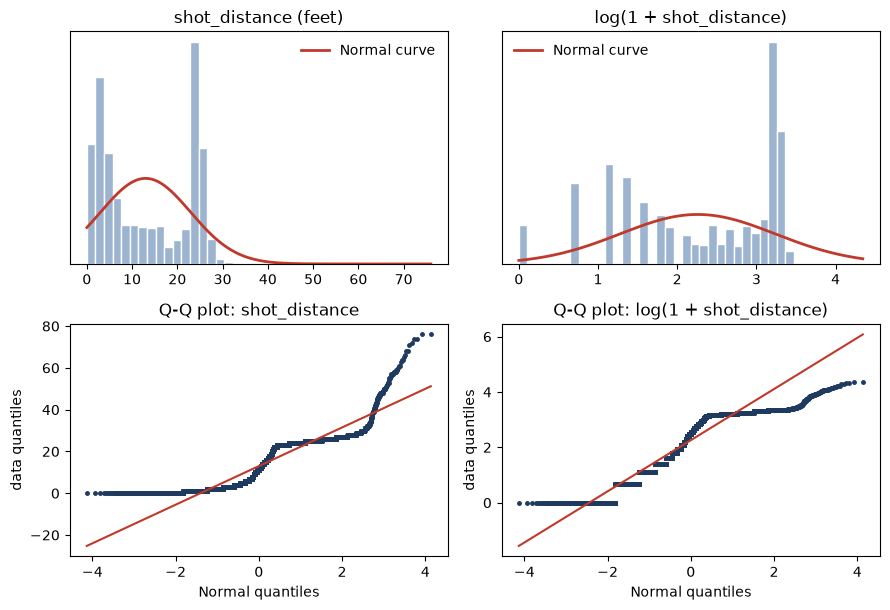

In [6]:
d = df["shot_distance"]
ld = np.log1p(d)

fig, ax = plt.subplots(2, 2, figsize=(9, 6.2))
top = [(ax[0, 0], d, "shot_distance (feet)"),
		(ax[0, 1], ld, "log(1 + shot_distance)")]
for a, v, title in top:
	a.hist(v, bins=40, density=True,
		color="#9db4d1", edgecolor="white")
	xs = np.linspace(v.min(), v.max(), 200)
	a.plot(xs, stats.norm.pdf(xs, v.mean(), v.std()),
		color="#c0392b", lw=2, label="Normal curve")
	a.set_title(title); a.set_yticks([])
	a.legend(frameon=False)
bottom = [(ax[1, 0], d, "Q-Q plot: shot_distance"),
(ax[1, 1], ld, "Q-Q plot: log(1 + shot_distance)")]
for a, v, title in bottom:
	stats.probplot(v, dist="norm", plot=a)
	a.get_lines()[0].set_markersize(2.5)
	a.get_lines()[0].set_color("#1f3a5f")
	a.get_lines()[1].set_color("#c0392b")
	a.set_title(title)
	a.set_xlabel("Normal quantiles")
	a.set_ylabel("data quantiles")
plt.tight_layout()
plt.savefig("fig_distance.png", dpi=200)
plt.show()

## AI Note
I used AI (Claude) to help write and organize the code in this notebook. I can explain every line: what `.cov()` computes, why the matrix is symmetric, why both sides of the Var(X + Y) formula match, and how to read the histograms and Q-Q plots. The interpretations written on my slides are my own.